# Stitch multiple multiplexed OME-TIFF componants to for an image.

This tutorial walks through `cosmix.stitch`:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import ImageColor
from pathlib import Path

from cosmix.bioformats.draw import blend_colors
from cosmix.bioformats.reader import get_slide_reader

## 1. Open componant and inspect its metadata

In [2]:
COMPONANT_DIR = "/cluster/CBIO/data2/mblons/tipit/data/multiplex/fluorescence/component/PANEL TLS/COMPONENT PANEL TLS"

In [3]:
def extract_act_tag(str, prefix: str, size=10):
    substr = str.removeprefix(prefix)
    return substr[:size]


def get_id(path: str | Path, prefix: str):
    if isinstance(path, str):
        path = Path(path)

    files = sorted(path.glob("*.tif*"))
    ids = [extract_act_tag(file.stem, prefix) for file in files]
    uniques = [i for i in set(ids)]
    return uniques

In [6]:
IDS = get_id(COMPONANT_DIR, prefix="TIPIT_TLS-")
SELECTED_ID = IDS[0]

In [7]:
componant_files = sorted(Path(COMPONANT_DIR).glob(f"*{SELECTED_ID}*"))
print(f"N = {len(componant_files)} componants found for sample: {SELECTED_ID}")

N = 38 componants found for sample: A_AAAA1244


In [9]:
from cosmix.bioformats.stitch import read_tile_region
read_tile_region(componant_files[0])

TileRegion(file_path=PosixPath('/cluster/CBIO/data2/mblons/tipit/data/multiplex/fluorescence/component/PANEL TLS/COMPONENT PANEL TLS/TIPIT_TLS-A_AAAA1244_[39506,11754]_component_data.tif'), x_position=78521.70586819526, y_position=23060.288532547067, width=1344, height=1004, x_resolution=2.004624110280836, y_resolution=2.004624110280836, x_coord=78522, y_coord=23060)

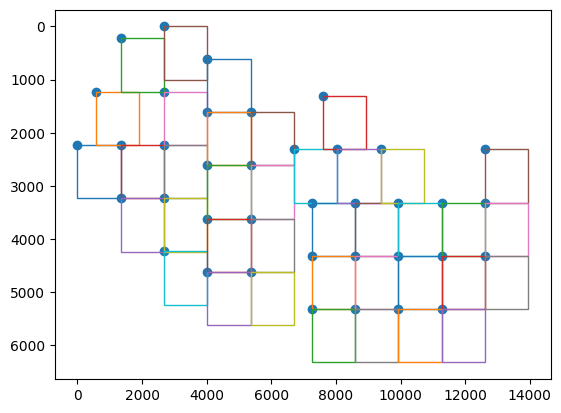

<Axes: >

In [ ]:
from cosmix.bioformats.stitch import plot_tile_regions
from cosmix.bioformats.stitch import zero_center_regions, collect_tile_regions

regions = zero_center_regions(collect_tile_regions(componant_files))

_ = plot_tile_regions(regions)

In [23]:
from cosmix.bioformats.stitch import stitch_tile_regions

# Stitch and save
SLIDE_PATH = f"{SELECTED_ID}.ome.tif"
stitch_tile_regions(regions, dst=Path(SLIDE_PATH), normalize=True)

## 1. Open the slide and inspect its metadata

In [24]:
slide = get_slide_reader(SLIDE_PATH)
print(slide)

OpenOME(name='A_AAAA1244', dimensions=(13955, 6322), channels=7, levels=6, mpp=0.4988)


In [25]:
print(f"is multiplex: {slide.is_multiplex}")
print(f"is rgb: {slide.is_rgb}")
print(f"mpp: {slide.mpp}")
print(f"mag: {slide.magnification}")
print(f"dimensions: {slide.dimensions}")
print(f"format: {slide.format}")
print(f"pages: {slide.pages}")
print(f"channels: {slide.channel_count}")
print(f"names: {slide.channel_names}")
print(f"OME colors: {slide.channel_colors.tolist()}")

is multiplex: True
is rgb: False
mpp: 0.4988
mag: 20
dimensions: (13955, 6322)
format: ushort
pages: 7
channels: 7
names: ['DAPI', 'pnad (Opal 650)', 'CD3 (Opal 690)', 'CD20 (Opal 520)', 'DC (Opal 570)', 'CD21 (Opal 620)', 'Autofluorescence']
OME colors: [[0, 17, 255], [255, 255, 0], [255, 0, 255], [0, 255, 0], [255, 128, 0], [255, 0, 0], [0, 0, 0]]


The raw `Pixels` attributes of the OME-XML are available with `get_pixels_metadata`.

In [26]:
slide.get_pixels_metadata()

{'size_x': 13955,
 'size_y': 6322,
 'size_z': 1,
 'size_c': 7,
 'size_t': 1,
 'type': 'uint16',
 'dimension_order': 'XYZCT',
 'physical_size_x': 0.49884663906387205,
 'physical_size_y': 0.49884663906387205,
 'physical_size_unit': 'µm'}

## 2. Resolution pyramid

In [27]:
print(f"level count: {slide.level_count}")
for level, (dims, downsample) in enumerate(
    zip(slide.level_dimensions, slide.level_downsamples)
):
    print(f"level {level}: {dims}, downsample {downsample:.2f}")

level count: 6
level 0: (13955, 6322), downsample 1.00
level 1: (6977, 3161), downsample 2.00
level 2: (3488, 1580), downsample 4.00
level 3: (1744, 790), downsample 8.00
level 4: (872, 395), downsample 16.01
level 5: (436, 197), downsample 32.09


## 3. Single channel thumbnails

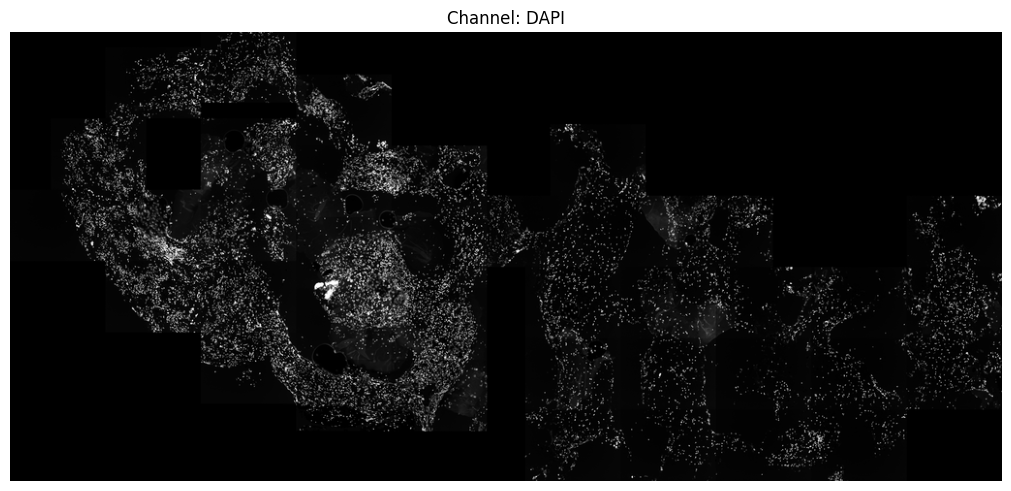

In [28]:
hoechst = slide.get_single_channel_thumbnail(size=(1024, 1024), key="DAPI", numpy=True)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(hoechst, aspect="equal", cmap="gray")
ax.set_title("Channel: DAPI")
ax.set_axis_off()
plt.show()

thumbnail shape: (464, 1024, 7)


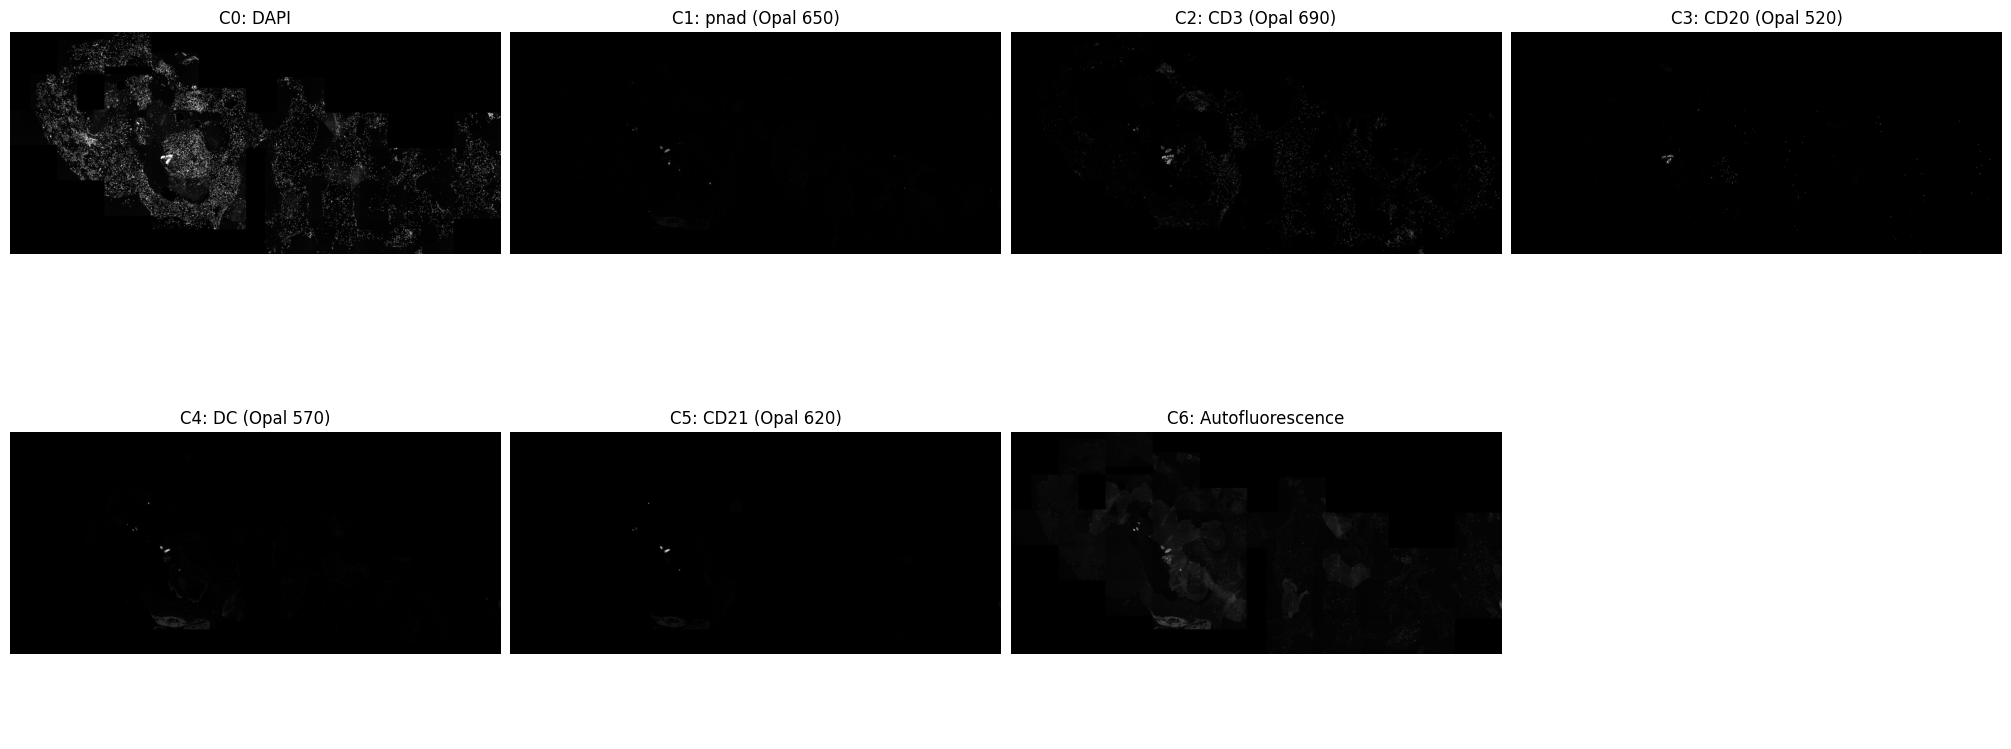

In [29]:
thumbnail = slide.get_thumbnail(size=(1024, 1024), numpy=True)
print(f"thumbnail shape: {thumbnail.shape}")

n_cols = 4
n_rows = int(np.ceil(slide.channel_count / n_cols))
fig, ax = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), layout="constrained")
ax = ax.ravel()
for idx, chnl in enumerate(slide.channel_names):
    ax[idx].imshow(thumbnail[:, :, idx], aspect="equal", cmap="gray")
    ax[idx].set_title(f"C{idx}: {chnl}")
for i in range(len(ax)):
    ax[i].set_axis_off()
plt.show()

## 4. Color blending

level 4: (395, 872, 7), uint16


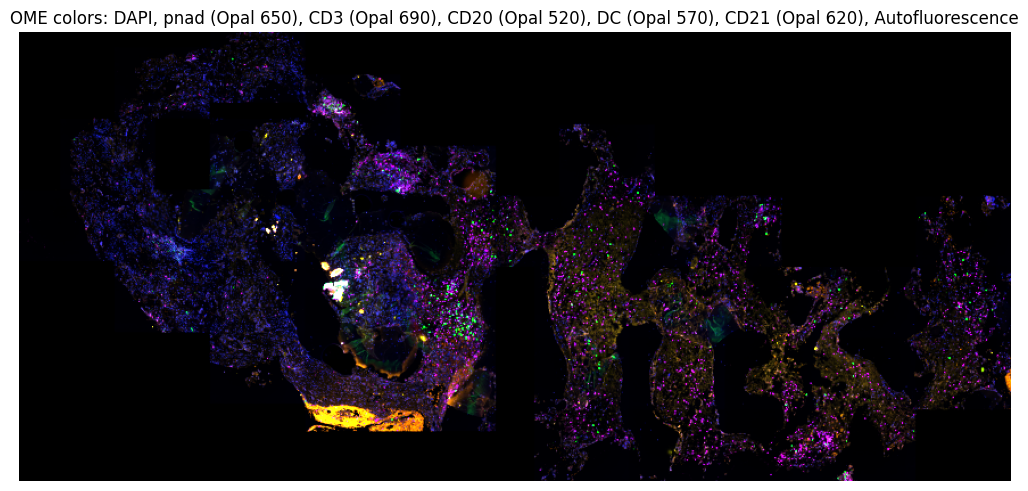

In [30]:
level = slide.get_best_level_for_downsample(32)[0]
fluo = slide.read_whole(level=level)
print(f"level {level}: {fluo.shape}, {fluo.dtype}")

gammas = np.ones_like(slide.channel_names)
blended_ome = blend_colors(
    fluo, slide.channel_colors, density_ratio=1e-4, gammas=gammas
)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(blended_ome, aspect="equal")
ax.set_title(f"OME colors: {', '.join(slide.channel_names)}")
ax.set_axis_off()
plt.show()

tissue center (level 0): (5105, 3393)
level 0: location (4593, 2881), shape (1024, 1024, 7)
level 2: location (3056, 1344), shape (1024, 1024, 7)


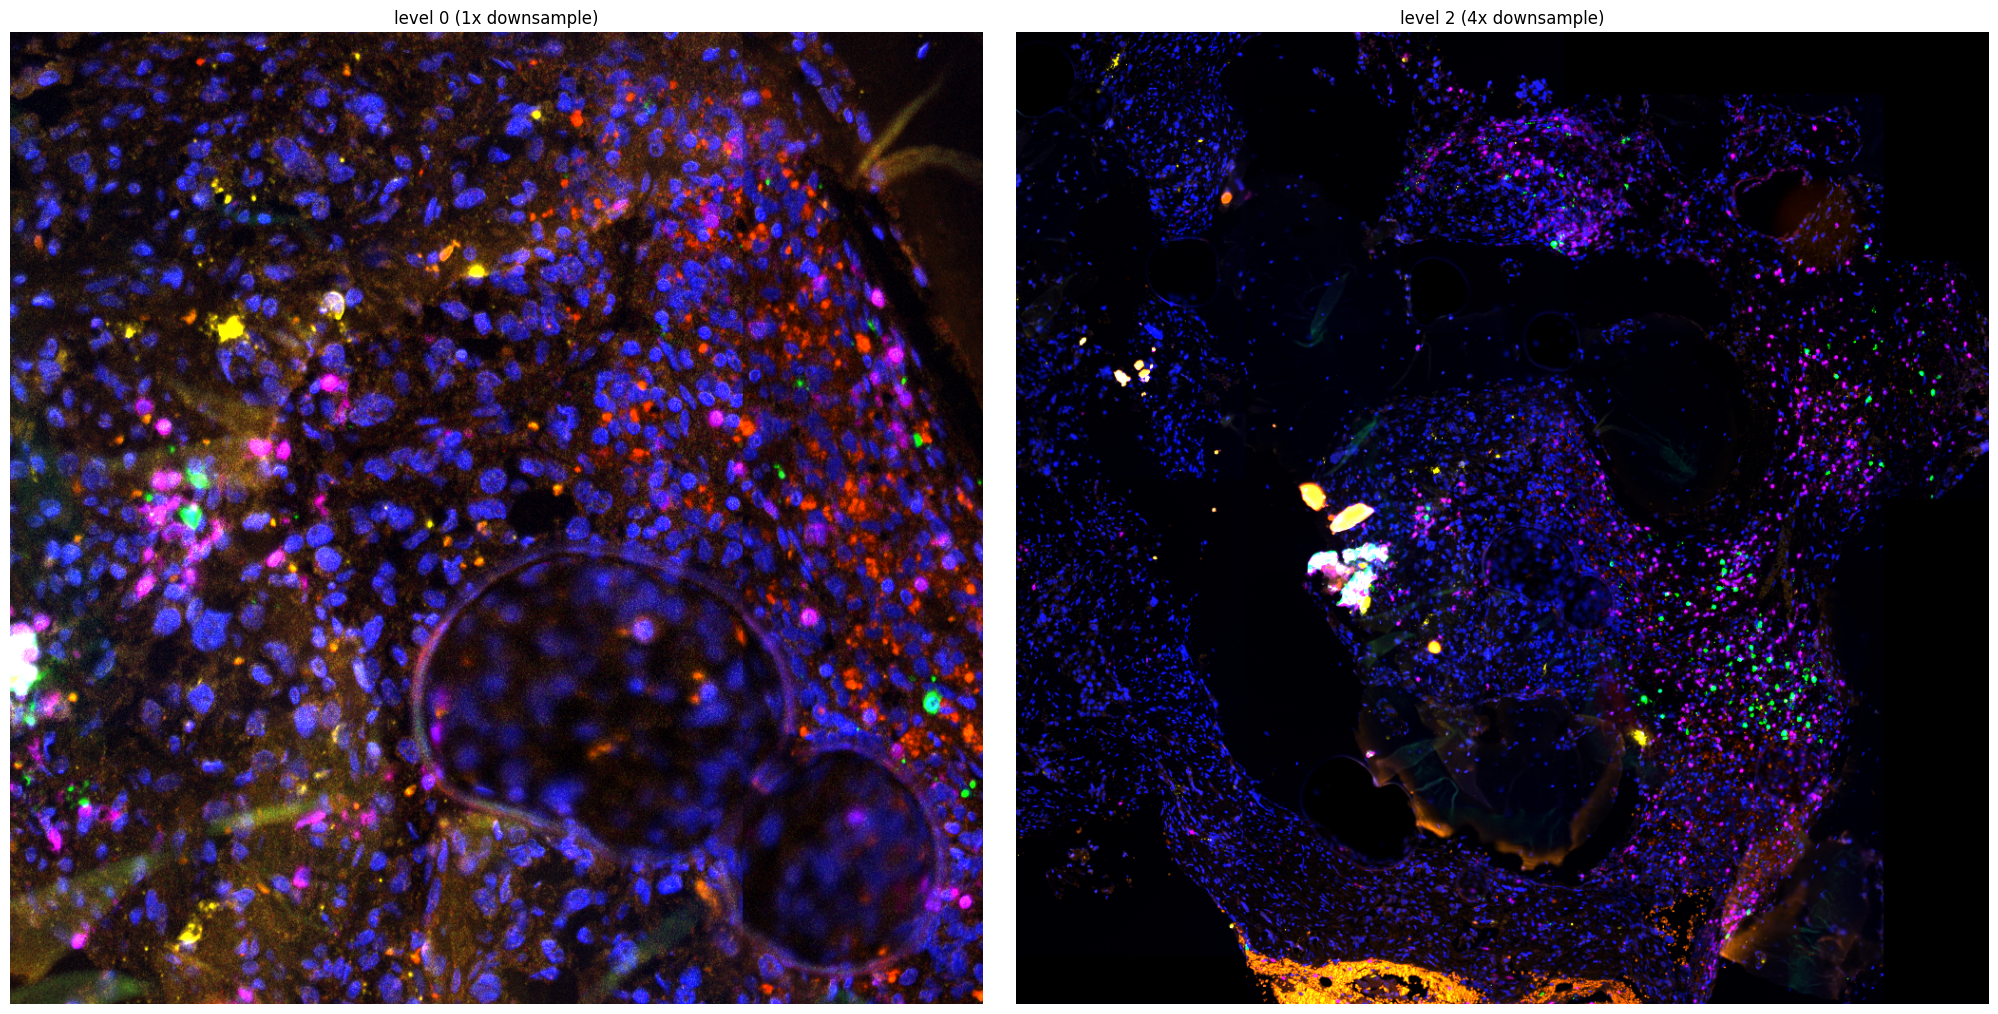

In [31]:
dapi = fluo[:, :, slide.get_channel_index("DAPI")]
ys, xs = np.nonzero(dapi > dapi.mean())
downsample = slide.level_downsamples[level]
center = (int(np.median(xs) * downsample), int(np.median(ys) * downsample))
print(f"tissue center (level 0): {center}")

region_size = (1024, 1024)
regions = {}
for region_level in [0, 2]:
    # shift the location so that the region is centered on `center`
    half = [s * slide.level_downsamples[region_level] / 2 for s in region_size]
    location = (int(center[0] - half[0]), int(center[1] - half[1]))
    regions[region_level] = slide.read_region(location, level=region_level, size=region_size)
    print(f"level {region_level}: location {location}, shape {regions[region_level].shape}")

fig, ax = plt.subplots(1, len(regions), figsize=(10 * len(regions), 10), layout="constrained")
for i, (region_level, region) in enumerate(regions.items()):
    ax[i].imshow(blend_colors(region, slide.channel_colors, gammas=gammas), aspect="equal")
    ax[i].set_title(f"level {region_level} ({slide.level_downsamples[region_level]:.0f}x downsample)")
    ax[i].set_axis_off()
plt.show()